# 쇼핑몰 단골 찾기: 고객 분석 보고서

쇼핑몰 거래 기록을 정리·분석해 **"누가 최근에, 자주, 많이 사는가"** 로 고객을 나누고, 그룹별 마케팅 전략을 제안하는 분석 보고서입니다.

| 데이터 | 출처 | 라이선스 | 쓰임 |
|---|---|---|---|
| Online Retail II (거래 기록) | UCI Machine Learning Repository, Daqing Chen (DOI 10.24432/C5CG6D) | CC BY 4.0 | 결측치·이상치·통계·RFM |
| Fashion Product Images (Small) | Kaggle, Param Aggarwal | MIT (Kaggle 페이지 표기) | 상품 정보·이미지 피처 |

> 두 데이터는 서로 연결되지 않습니다(같은 상품이 아님). 그래서 **거래 분석과 이미지 피처 실습은 별도 데이터로** 진행합니다.

**목차** (단계가 진행되면서 채워집니다)
1. 데이터 개요
2. 정제와 결측치 처리
3. 이상치 탐지와 처리
4. 텍스트·이미지 피처 ← 현재
5. 통계 분석과 시각화
6. RFM 고객 세분화

## 0. 준비

사용할 도구를 불러오고 데이터 폴더 위치를 정합니다.

In [1]:
import pandas as pd            # 표 데이터를 다루는 라이브러리 (pd 라는 짧은 이름으로 부름)
from pathlib import Path       # 파일 경로를 다루는 파이썬 기본 도구

DATA_DIR = Path("..") / "data"             # 이 노트북(notebooks/) 기준으로 한 칸 위의 data 폴더
pd.set_option("display.max_columns", 20)   # 컬럼이 많아도 ... 로 줄이지 않고 모두 보여주기
pd.set_option("display.width", 200)        # 한 줄에 보여줄 글자 폭

## 1. 거래 데이터: Online Retail II

영국 온라인 선물용품 쇼핑몰의 2009-12 ~ 2011-12 거래 기록입니다. 이 데이터로 고객을 분석합니다.

### 1-0. 불러오기

CSV를 읽을 때 두 가지를 미리 알려줍니다.
- `Invoice`(주문번호)와 `StockCode`(상품코드)는 `C489449`처럼 **글자가 섞인 값**이 있어서, 숫자가 아니라 글자(`str`)로 읽습니다.
- `InvoiceDate`는 글자가 아니라 **날짜 형식**으로 읽어야 기간 계산을 할 수 있습니다(`parse_dates`).

In [2]:
retail = pd.read_csv(
    DATA_DIR / "online_retail_II.csv",
    dtype={"Invoice": "str", "StockCode": "str"},   # 'C'로 시작하는 주문번호가 있어 글자로 읽음
    parse_dates=["InvoiceDate"],                    # 날짜 글자를 진짜 날짜로 변환
)
print(f"행 {retail.shape[0]:,}개 × 컬럼 {retail.shape[1]}개")

행 1,067,371개 × 컬럼 8개


### 1-1. `head()`: 맨 위 5줄

데이터가 어떤 모양인지 눈으로 먼저 확인합니다.

In [3]:
retail.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


> **해석**
>
> **수치 근거:** 맨 위 5줄이 모두 주문번호 `489434`, 고객 `13085`, 시각 `2009-12-01 07:45`로 같고, 상품(`StockCode`)만 서로 다릅니다.
>
> **시사점:** 한 줄은 "한 주문 안의 상품 한 종류"입니다. 그래서 고객이 몇 번 샀는지(Frequency)는 줄 수가 아니라 **고유 주문번호의 개수**로 세어야 합니다.

### 1-2. `info()`: 구조와 결측 확인

컬럼별로 값이 몇 개 들어 있는지(`Non-Null Count`)와 자료형(`Dtype`)을 보여줍니다. 전체 행 수보다 적으면 그만큼 **비어 있다(결측)** 는 뜻입니다.

In [4]:
retail.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  str           
 1   StockCode    1067371 non-null  str           
 2   Description  1062989 non-null  str           
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 65.1 MB


> **해석**
>
> **수치 근거:** 전체 1,067,371행 × 8컬럼이며, `Customer ID`는 824,364행에만 값이 있어 **243,007행(22.77%)이 비어 있습니다.** `Description`(상품명)은 4,382행(0.41%)이 비어 있습니다. 자료형은 글자 4개, 소수 2개, 정수 1개, 날짜 1개입니다.
>
> **시사점:** 수치·범주·날짜·텍스트가 섞여 있어 "3가지 이상 유형" 조건을 충족합니다. 고객 ID가 없는 행은 "누가 샀는지" 알 수 없어 고객 분석(RFM)에서 제외해야 하고(전체의 약 1/4에 가까움), 상품명 결측은 0.41%로 적어 정제 뒤에도 남는지 점검합니다(2장).
>
> (`Customer ID`가 정수가 아니라 소수형 `float64`인 이유: 값이 비어 있는 행(`NaN`)을 담으려면 소수형이어야 하기 때문입니다.)

### 1-3. `describe()`: 숫자 요약

숫자 컬럼의 개수(`count`), 평균(`mean`), 표준편차(`std`), 최솟값(`min`), 25%·50%(중앙값)·75% 지점, 최댓값(`max`)을 한 번에 보여줍니다. `Customer ID`는 식별 번호라 평균이 의미 없어서 뺐습니다.

In [5]:
retail[["Quantity", "Price"]].describe().style.format("{:,.2f}")   # 천 단위 쉼표, 소수 둘째 자리까지

,Quantity,Price
count,"1,067,371.00","1,067,371.00"
mean,9.94,4.65
std,172.71,123.55
min,"-80,995.00","-53,594.36"
25%,1.00,1.25
50%,3.00,2.10
75%,10.00,4.15
max,"80,995.00","38,970.00"


describe의 숫자가 왜 그런지 확인하려고, 극단값과 음수 행을 직접 들여다봅니다.

In [6]:
is_cancel = retail["Invoice"].str.startswith("C")      # 주문번호가 'C'로 시작 = 취소 주문
neg_qty = retail["Quantity"] < 0                        # 수량이 음수인 행

print(f"수량이 음수인 행:        {neg_qty.sum():>7,}개 ({neg_qty.mean():.2%})")
print(f"  └ 그중 취소(C) 주문:   {(neg_qty & is_cancel).sum():>7,}개")
print(f"  └ 그중 취소 표시 없음: {(neg_qty & ~is_cancel).sum():>7,}개")
print(f"가격이 0인 행:           {(retail['Price'] == 0).sum():>7,}개 ({(retail['Price'] == 0).mean():.2%})")
print(f"가격이 음수인 행:        {(retail['Price'] < 0).sum():>7,}개")
print(f"거래 기간: {retail['InvoiceDate'].min()} ~ {retail['InvoiceDate'].max()}")
print()
print("▶ 수량이 가장 작은 행 / 가장 큰 행")
print(retail.loc[[retail["Quantity"].idxmin(), retail["Quantity"].idxmax()],
                 ["Invoice", "Description", "Quantity", "Price", "Customer ID"]])
print()
print("▶ 가격이 가장 작은 행")
print(retail.loc[[retail["Price"].idxmin()], ["Invoice", "Description", "Quantity", "Price"]])

수량이 음수인 행:         22,950개 (2.15%)
  └ 그중 취소(C) 주문:    19,493개
  └ 그중 취소 표시 없음:   3,457개
가격이 0인 행:             6,202개 (0.58%)
가격이 음수인 행:              5개
거래 기간: 2009-12-01 07:45:00 ~ 2011-12-09 12:50:00

▶ 수량이 가장 작은 행 / 가장 큰 행
         Invoice                  Description  Quantity  Price  Customer ID
1065883  C581484  PAPER CRAFT , LITTLE BIRDIE    -80995   2.08      16446.0
1065882   581483  PAPER CRAFT , LITTLE BIRDIE     80995   2.08      16446.0

▶ 가격이 가장 작은 행
        Invoice      Description  Quantity     Price
179403  A506401  Adjust bad debt         1 -53594.36


> **해석**
>
> **수치 근거:** `Quantity`는 중앙값 3, 평균 9.94, 75% 지점 10인데 최댓값은 80,995, 최솟값은 −80,995입니다. `Price`도 중앙값 2.10, 평균 4.65인데 최솟값 −53,594.36, 최댓값 38,970입니다. 수량이 음수인 행은 22,950개(2.15%)이고 그중 19,493개가 주문번호가 `C`로 시작하는 취소 주문입니다. 가격이 0인 행도 6,202개(0.58%) 있습니다.
>
> **시사점:** `Quantity`는 평균(9.94)이 중앙값(3)의 3배가 넘어 **오른쪽으로 길게 치우친 분포**이고, 극단값이 평균과 표준편차를 끌고 갑니다. 그래서 이상치 판단에는 극단값에 덜 흔들리는 **사분위수 기반 IQR**이 적합합니다(3장). 또 취소·음수·0 이하 행은 매출 계산을 왜곡하므로 정제 단계에서 제거합니다(2장).
>
> **눈여겨볼 두 행:**
> - 수량의 최댓값 80,995와 최솟값 −80,995는 **같은 상품·같은 고객(16446)이 대량 주문(`581483`)했다가 곧바로 취소(`C581484`)한 쌍**입니다.
> - 가격의 최솟값 −53,594.36은 상품명이 `Adjust bad debt`(부실채권 조정)인 **회계 조정 행**이라 실제 판매가 아닙니다.

## 2. 상품 데이터: Fashion Product Images

패션 상품 약 4.4만 개의 정보 표(`styles.csv`)입니다. 이 표의 `id`와 같은 이름의 사진 파일(`images/{id}.jpg`)이 있어, 나중에 사진을 숫자로 바꾸는 실습(4장)에 씁니다.

### 2-0. 불러오기

`styles.csv`는 일부 상품명에 쉼표(`,`)가 들어 있는데 따옴표로 감싸지 않아, 컬럼 수가 어긋나는 줄이 **22줄** 있습니다. 이 줄들은 건너뛰고(`on_bad_lines="skip"`) 읽으며, 전체의 0.05%라 분석에는 영향이 거의 없습니다.

In [7]:
styles = pd.read_csv(
    DATA_DIR / "fashion_small" / "styles.csv",
    on_bad_lines="skip",          # 컬럼 수가 어긋난 22줄은 건너뜀
)
print(f"행 {styles.shape[0]:,}개 × 컬럼 {styles.shape[1]}개")

행 44,424개 × 컬럼 10개


### 2-1. `head()`

In [8]:
styles.head()

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


> **해석**
>
> **수치 근거:** 한 줄이 상품 한 개입니다(예: `id` 15970은 남성 네이비 셔츠). 컬럼은 `id`, `gender`, `masterCategory`, `subCategory`, `articleType`, `baseColour`, `season`, `year`, `usage`, `productDisplayName` 10개입니다.
>
> **시사점:** `id`가 `images/15970.jpg`처럼 사진 파일 이름과 같아서, 이 표와 이미지를 `id`로 연결할 수 있습니다(4장). 상품명(`productDisplayName`)은 글자 수·단어 수를 센 파생 변수의 재료가 됩니다.

### 2-2. `info()`

In [9]:
styles.info()

<class 'pandas.DataFrame'>
RangeIndex: 44424 entries, 0 to 44423
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  44424 non-null  int64  
 1   gender              44424 non-null  str    
 2   masterCategory      44424 non-null  str    
 3   subCategory         44424 non-null  str    
 4   articleType         44424 non-null  str    
 5   baseColour          44409 non-null  str    
 6   season              44403 non-null  str    
 7   year                44423 non-null  float64
 8   usage               44107 non-null  str    
 9   productDisplayName  44417 non-null  str    
dtypes: float64(1), int64(1), str(8)
memory usage: 3.4 MB


> **해석**
>
> **수치 근거:** 44,424행 × 10컬럼이고, 결측은 `usage` 317개(0.71%), `season` 21개, `baseColour` 15개, `productDisplayName` 7개, `year` 1개로 **모두 1% 미만**입니다.
>
> **시사점:** 결측이 적어 지워도 분석에 큰 영향은 없지만, 오히려 "그룹별 대치"를 보여주기에 알맞은 대상입니다. 같은 품목(`articleType`)끼리 묶어 가장 흔한 값으로 채우는 방식을 2장에서 적용합니다.

### 2-3. `describe()`와 분포 확인

숫자 컬럼은 `year` 하나뿐이고(`id`는 식별 번호라 평균이 의미 없음), 나머지는 글자(범주)라서 값별 개수(`value_counts`)로 분포를 봅니다.

In [10]:
print(styles[["year"]].describe().round(1))
print()
print("▶ year 상위 3개\n", styles["year"].value_counts().head(3), sep="")
print()
print("▶ gender\n", styles["gender"].value_counts(), sep="")
print()
print("▶ masterCategory 상위 3개\n", styles["masterCategory"].value_counts().head(3), sep="")

          year
count  44423.0
mean    2012.8
std        2.1
min     2007.0
25%     2011.0
50%     2012.0
75%     2015.0
max     2019.0

▶ year 상위 3개
year
2012.0    16288
2011.0    13672
2016.0     6006
Name: count, dtype: int64

▶ gender
gender
Men       22147
Women     18631
Unisex     2161
Boys        830
Girls       655
Name: count, dtype: int64

▶ masterCategory 상위 3개
masterCategory
Apparel        21397
Accessories    11274
Footwear        9219
Name: count, dtype: int64


> **해석**
>
> **수치 근거:** `year`는 2007~2019년이고 중앙값은 2012년이며, 2012년(16,288개)과 2011년(13,672개)이 전체의 약 67%를 차지합니다. 성별은 Men 22,147개(49.9%), Women 18,631개(41.9%)이고, 대분류는 Apparel(의류) 21,397개(48.2%)로 가장 많습니다.
>
> **시사점:** 특정 연도·성별·의류에 치우친 표본이므로, 이후 이미지 평균·표준편차 같은 결과를 말할 때 "의류 중심 상품 사진"이라는 한계를 함께 밝혀야 합니다.

## 3. 1장에서 알게 된 것과 다음 단계

| 발견 | 근거 | 다음 단계에서 할 일 |
|---|---|---|
| 한 주문에 여러 줄이 있음 | 맨 위 5줄이 같은 주문번호 | 구매 횟수(F)는 고유 주문번호 수로 계산 (6장) |
| 고객 ID가 22.77% 비어 있음 | `info()` | RFM 대상에서 제외 (2장, 6장) |
| 취소·음수·0 가격 행 | 수량 음수 22,950개, 가격 0 6,202개 | 정제로 제거 (2장) |
| 극단값이 평균을 끌고 감 | 수량 ±80,995 | IQR로 이상치 탐지 (3장) |
| 두 시트가 같은 기간을 중복 포함 | 2010-12-01~09의 22,523행씩 겹침 (원본 점검에서 확인) | 중복 행 제거 후 개수 기록 (2장) |
| 상품 표에 결측이 있음 | `usage` 317개 등 | 그룹별 대치 (2장) |
| `styles.csv` 22줄의 형식 오류 | 상품명 속 쉼표 | 건너뛰고 개수를 README에 기록 |

---

# 2장. 정제와 결측치 처리

1장에서 발견한 문제(같은 행 중복, 취소 주문, 수량·단가가 0 이하인 행, 빈칸)를 고칩니다.

**왜 클래스(`DataAnalyzer`)로 만드나?** 정제·이상치·RFM 코드는 같은 모양으로 반복해서 쓰입니다. 노트북 칸마다 복사해 두면 고칠 때 여러 군데를 손봐야 하므로, `src/pipeline.py`에 한 번만 만들어 두고 노트북에서는 불러다 씁니다. 표 하나당 `DataAnalyzer`를 하나씩 만들기 때문에, 같은 도구를 거래표와 상품표에 경로만 바꿔 다시 쓸 수 있습니다.

## 2장-1. 클래스로 거래 데이터 불러오기

`load_data()`는 1장에서 쓴 읽기 옵션(글자로 읽기, 날짜 변환)을 그대로 적용하고, 컬럼 이름을 공백 없는 이름으로 한 번에 바꿉니다. 바꾸는 것은 메모리에 읽어 온 표의 이름뿐이고, 디스크의 CSV 파일은 그대로입니다.

| 원래 이름 | 새 이름 | 원래 이름 | 새 이름 |
|---|---|---|---|
| `Invoice` | `invoice` | `Price` | `price` |
| `StockCode` | `stock_code` | `Customer ID` | `customer_id` |
| `Description` | `description` | `InvoiceDate` | `order_date` |
| `Quantity` | `quantity` | `Country` | `country` |

이름을 바꾸는 이유는 `Customer ID`처럼 공백이 있는 이름은 코드에서 쓰기 불편하고, 과제가 요구하는 컬럼명(`customer_id`, `order_date`, `amount`)과 맞추기 위해서입니다.

In [11]:
import sys
sys.path.append(str(Path("..").resolve()))      # 한 칸 위(프로젝트 폴더)를 파이썬이 찾는 곳에 추가 → src 폴더를 불러올 수 있음

from src.pipeline import DataAnalyzer, RETAIL_RENAME

retail_analyzer = DataAnalyzer(DATA_DIR / "online_retail_II.csv")   # 거래표용 도구 만들기 (아직 읽지는 않음)
retail_analyzer.load_data(
    date_cols=["InvoiceDate"],                      # 날짜로 변환할 컬럼 (CSV에 적힌 원래 이름)
    rename=RETAIL_RENAME,                           # 읽은 뒤 컬럼 이름을 새 이름으로 바꿈
    dtype={"Invoice": "str", "StockCode": "str"},   # 1장과 같은 옵션: 'C'가 섞인 번호는 글자로
)
print(f"행 {retail_analyzer.df.shape[0]:,}개 × 컬럼 {retail_analyzer.df.shape[1]}개")
print("컬럼:", list(retail_analyzer.df.columns))

행 1,067,371개 × 컬럼 8개
컬럼: ['invoice', 'stock_code', 'description', 'quantity', 'order_date', 'price', 'customer_id', 'country']


## 2장-2. 거래 데이터 정제: `clean_transactions()`

네 가지를 **차례로** 지우고, 단계마다 몇 행을 지웠는지 기록합니다. 마지막으로 한 줄의 금액 `amount = quantity × price`를 만듭니다.

| 순서 | 지우는 행 | 이유 |
|---|---|---|
| ① | 완전히 같은 행 | 원본 엑셀의 두 시트가 2010-12-01~09 기간을 겹쳐 갖고 있어 같은 거래가 두 번 계산됩니다(원본 점검: 시트 사이 중복 22,202행 + 시트 안에서 같은 줄이 반복된 12,133행). 시트 안 반복이 실제 이중 입력인지 구분할 수 없어 함께 지우고, 개수를 기록합니다. |
| ② | 취소 주문(주문번호가 `C`로 시작) | 수량이 음수로 기록돼 매출과 구매 횟수를 왜곡합니다. |
| ③ | 수량이 0 이하인 행 | 취소 표시 없이 음수로 들어간 조정 행입니다. |
| ④ | 단가가 0 이하인 행 | 무료 지급·회계 조정 행이라 실제 판매가 아닙니다(1장에서 본 `Adjust bad debt` 행의 단가는 −53,594.36). |

고객 번호가 빈 행은 여기서 지우지 않습니다. 매출·국가별 집계에는 쓸 수 있고, 고객 단위 분석(RFM)을 할 때만 따로 제외합니다.

In [12]:
log = retail_analyzer.clean_transactions()       # 정제 실행 + 단계별 제거 행 수 표를 돌려받음
log.style.format({"제거한 행": "{:,}", "남은 행": "{:,}"}).hide(axis="index").set_uuid("cleaning_log")

단계,제거한 행,남은 행
정제 전 (원본),0,"1,067,371"
완전히 같은 행(중복) 제거,"34,335","1,033,036"
취소 주문(주문번호 C…) 제거,"19,104","1,013,932"
수량 0 이하 제거,"3,393","1,010,539"
단가 0 이하 제거,"2,626","1,007,913"


### 정제 결과 확인

정제가 말한 대로 됐는지 코드로 직접 세어 봅니다.

In [13]:
clean = retail_analyzer.df                       # 정제가 끝난 표
raw_rows = len(retail)                           # 1장에서 읽은 원본 표의 행 수
removed = raw_rows - len(clean)
print(f"정제 전 {raw_rows:,}행 → 정제 후 {len(clean):,}행  (제거 {removed:,}행, 전체의 {removed / raw_rows:.2%})")
print(f"단계별 제거 합계가 전체 제거 수와 같은가: {log['제거한 행'].sum() == removed}")
print()
print("▶ 정제가 말한 대로 됐는지 확인")
print(f"  수량 최솟값 {clean['quantity'].min()}, 단가 최솟값 {clean['price'].min()}   (둘 다 0보다 커야 함)")
print(f"  'C'로 시작하는 주문번호: {clean['invoice'].str.startswith('C').sum()}개   (0이어야 함)")
print(f"  완전히 같은 행: {clean.duplicated().sum()}개   (0이어야 함)")
print(f"  amount = quantity × price 가 모든 행에서 성립: {(clean['amount'] == clean['quantity'] * clean['price']).all()}")
print()
print("▶ 정제로 해결되지 않고 남은 빈칸")
print(f"  고객 번호(customer_id): {clean['customer_id'].isna().sum():,}행 ({clean['customer_id'].isna().mean():.2%})")
print(f"  상품명(description):    {clean['description'].isna().sum():,}행   (1장에서는 4,382행이었음)")
print()
print("▶ 규칙으로 걸러지지 않은 비판매 행")
print(clean.loc[clean["description"] == "Adjust bad debt", ["invoice", "description", "quantity", "price", "amount"]].to_string())
non_digit = ~clean["stock_code"].str.match(r"^\d{5}")       # 숫자 5자리로 시작하지 않는 상품코드
share = clean.loc[non_digit, "amount"].sum() / clean["amount"].sum()
print(f"\n숫자 5자리로 시작하지 않는 상품코드: {non_digit.sum():,}행 ({non_digit.mean():.2%}), 금액 합이 전체의 {share:.1%}")
print(clean.loc[non_digit].groupby("stock_code")["description"].agg(["size", "first"]).sort_values("size", ascending=False).head(5).to_string())

정제 전 1,067,371행 → 정제 후 1,007,913행  (제거 59,458행, 전체의 5.57%)
단계별 제거 합계가 전체 제거 수와 같은가: True

▶ 정제가 말한 대로 됐는지 확인
  수량 최솟값 1, 단가 최솟값 0.001   (둘 다 0보다 커야 함)


  'C'로 시작하는 주문번호: 0개   (0이어야 함)


  완전히 같은 행: 0개   (0이어야 함)
  amount = quantity × price 가 모든 행에서 성립: True

▶ 정제로 해결되지 않고 남은 빈칸
  고객 번호(customer_id): 228,488행 (22.67%)
  상품명(description):    0행   (1장에서는 4,382행이었음)

▶ 규칙으로 걸러지지 않은 비판매 행
        invoice      description  quantity     price    amount
773540  A563185  Adjust bad debt         1  11062.06  11062.06



숫자 5자리로 시작하지 않는 상품코드: 4,699행 (0.47%), 금액 합이 전체의 4.1%
            size                                first
stock_code                                           
POST        1851                              POSTAGE
DOT         1415                       DOTCOM POSTAGE
M            846                               Manual
C2           267                             CARRIAGE
ADJUST        36  Adjustment by john on 26/01/2010 16


> **해석**
>
> **수치 근거:** 원본 1,067,371행에서 59,458행(5.57%)을 지워 1,007,913행이 남았습니다. 가장 많이 지운 것은 완전히 같은 행 34,335개(전체의 3.22%)이고, 그다음이 취소 주문 19,104행, 수량 0 이하 3,393행, 단가 0 이하 2,626행입니다.
>
> **시사점:** 같은 행을 지우지 않으면 같은 거래가 두 번 계산되어 금액(M)과 2010년 12월 매출이 부풀려집니다. 구매 횟수(F)는 주문번호를 세므로 영향이 작습니다. 그리고 정제 뒤에는 수량·단가가 모두 0보다 크고 취소 주문이 없어서, 이후 매출·RFM 계산이 취소·조정 행에 흔들리지 않습니다.
>
> **1장의 숫자와 다른 이유:** 단계마다 앞 단계에서 이미 지워진 행은 빼고 세기 때문입니다. 취소(`C`) 주문 행은 원래 19,494개인데 이 중 390행이 ①에서 중복으로 먼저 지워져 ②에서는 19,104행이 남아 있었습니다. 또 1장의 가격 0 이하 6,207행 가운데 3,457행은 수량도 음수라 ③에서 이미 지워졌고, 일부는 ①에서 빠져서 ④에서는 2,626행만 지웠습니다.
>
> **남은 문제 ①(빈칸):** 고객 번호가 빈 행은 정제 후에도 228,488행(22.67%) 남았습니다. 누구인지 알 수 없어 채울 수 없으므로 RFM 계산 때 제외합니다. 반대로 상품명 결측은 정제 후 0행이 되어, 거래표에서는 결측 대치를 보여 줄 대상이 남지 않습니다. 그룹별 대치는 상품표(Fashion)의 빈칸에 적용합니다.
>
> **남은 문제 ②(비판매 행):** 1장에서 본 `Adjust bad debt` 행 중 단가가 음수인 3행은 지워졌지만, 단가가 +11,062.06인 1행(주문 A563185)은 남아 있습니다. 단가가 양수라 "0 이하 제거" 규칙으로는 걸러지지 않기 때문입니다. 배송비(`POST`, `DOT`)·수기 입력(`M`)·운송(`C2`)·수수료(`BANK CHARGES`) 같은 상품이 아닌 코드도 남아 있어 금액으로는 전체의 약 4%를 차지합니다. 이런 행을 지울지는 이상치를 살펴보는 3장에서 `amount`의 극단값을 보며 정합니다.

## 2장-3. 결측치 처리: `handle_missing_values()`

빈칸(결측치)은 두 가지 원칙으로 다룹니다. **채워도 믿을 만하면 채우고, 채우면 거짓 정보가 되면 그대로 둡니다.** 먼저 정제가 끝난 거래표에 어떤 빈칸이 남았는지 `missing_report()`로 봅니다.

In [14]:
retail_analyzer.missing_report().style.format(
    {"결측 수": "{:,}", "결측 비율(%)": "{:.2f}"}).hide(axis="index").set_uuid("missing_retail")

컬럼,결측 수,결측 비율(%)
customer_id,"228,488",22.67
invoice,0,0.00
stock_code,0,0.00
description,0,0.00
quantity,0,0.00
order_date,0,0.00
price,0,0.00
country,0,0.00
amount,0,0.00


> **해석**
>
> **수치 근거:** 정제 후 거래표(1,007,913행)에서 빈칸이 남은 컬럼은 `customer_id` 228,488행(22.67%) 하나뿐이고, 나머지는 모두 0입니다. 1장에서 4,382행이던 상품명(`description`) 결측은 정제에서 모두 사라졌습니다.
>
> **시사점:** 고객 번호는 "누구인지"를 나타내는 식별 번호라서, 평균이나 최빈값으로 채우면 존재하지 않는 가짜 고객이 만들어집니다. 그래서 **채우지 않고** 고객 단위 분석(RFM, 6장) 때 제외합니다. 거래표에는 그룹별 대치를 보여 줄 빈칸이 남지 않았으므로, 그룹별 대치는 상품표(Fashion)에서 시연합니다.

### 그룹별로 채운다는 것: 8행 예제

빈칸을 **전체 평균**으로 채우면 신발 가격 빈칸에 셔츠 가격이 섞여 들어갑니다. 그래서 **같은 종류끼리 묶고, 그 묶음의 대표값**으로 채웁니다. 대표값을 구하는 방법은 세 가지이고 `strategy`로 고릅니다.

| strategy | 대표값 | 언제 쓰나 |
|---|---|---|
| `group_mean` | 평균 | 숫자이고 극단값이 없을 때 |
| `group_median` | 중앙값(가운데 값) | 숫자이고 극단값이 있을 때 (1장에서 본 평균 vs 중앙값과 같은 이유) |
| `group_mode` | 최빈값(가장 많이 나온 값) | 글자·범주처럼 숫자가 아닐 때 |

손으로 계산할 수 있게 8행만 만들었습니다. `kind`(종류)로 묶어서 `price`(숫자)와 `usage`(글자)의 빈칸을 채웁니다.

In [15]:
import numpy as np

toy = pd.DataFrame({
    "item":  list("abcdefgh"),
    "kind":  ["신발", "신발", "신발", "신발", "셔츠", "셔츠", "셔츠", "가방"],   # 묶는 기준
    "price": [100, 200, 600, np.nan, 30, 50, np.nan, np.nan],                  # 숫자 (빈칸 3개)
    "usage": ["운동", "운동", "일상", np.nan, "일상", "일상", np.nan, np.nan],   # 글자 (빈칸 3개)
})
toy

,item,kind,price,usage
0,a,신발,100.0,운동
1,b,신발,200.0,운동
2,c,신발,600.0,일상
3,d,신발,NaN,NaN
4,e,셔츠,30.0,일상
5,f,셔츠,50.0,일상
6,g,셔츠,NaN,NaN
7,h,가방,NaN,NaN


In [16]:
# 예제라서 CSV 대신 표를 직접 넣고, 전략마다 새 도구를 만들어 같은 표(toy)에 적용
demo_mean = DataAnalyzer("예제");   demo_mean.df = toy.copy()
demo_median = DataAnalyzer("예제"); demo_median.df = toy.copy()
demo_mode = DataAnalyzer("예제");   demo_mode.df = toy.copy()

log_mean = demo_mean.handle_missing_values("group_mean", "kind", "price")        # 종류별 평균으로 가격 채우기
log_median = demo_median.handle_missing_values("group_median", "kind", "price")  # 종류별 중앙값으로 가격 채우기
log_mode = demo_mode.handle_missing_values("group_mode", "kind", "usage")        # 종류별 최빈값으로 용도 채우기

toy.assign(
    price_평균=demo_mean.df["price"],
    price_중앙값=demo_median.df["price"],
    usage_최빈값=demo_mode.df["usage"],
)

,item,kind,price,usage,price_평균,price_중앙값,usage_최빈값
0,a,신발,100.0,운동,100.0,100.0,운동
1,b,신발,200.0,운동,200.0,200.0,운동
2,c,신발,600.0,일상,600.0,600.0,일상
3,d,신발,NaN,NaN,300.0,200.0,운동
4,e,셔츠,30.0,일상,30.0,30.0,일상
5,f,셔츠,50.0,일상,50.0,50.0,일상
6,g,셔츠,NaN,NaN,40.0,40.0,일상
7,h,가방,NaN,NaN,196.0,100.0,일상


In [17]:
# 이번 대치가 몇 칸을 어떻게 채웠는지 (그룹 값 vs 전체 값)
pd.concat([log_mean, log_median, log_mode]).style.hide(axis="index").set_uuid("toy_log")

컬럼,전략,묶는 기준,채우기 전 결측,그룹 값으로 채움,전체 값으로 채움,채운 후 결측
price,group_mean,kind,3,2,1,0
price,group_median,kind,3,2,1,0
usage,group_mode,kind,3,2,1,0


> **해석 (손으로 확인해 보세요)**
>
> - **신발** `price`: 값이 100·200·600이라 평균은 (100+200+600) ÷ 3 = **300**, 중앙값은 가운데인 **200**입니다. 600 하나가 평균을 끌어올린 것으로, 1장에서 본 평균 vs 중앙값과 같은 현상입니다.
> - **셔츠** `price`: 30과 50의 평균·중앙값은 모두 **40**입니다. `usage`는 둘 다 '일상'이라 최빈값은 **일상**입니다.
> - **신발** `usage`: 운동 2개, 일상 1개라 최빈값은 **운동**입니다.
> - **가방**: 그룹에 값이 하나도 없어 대표값을 못 구하므로 **전체 값**으로 채웁니다(전체 평균 196, 중앙값 100, 최빈값 '일상'). 결과 표의 "전체 값으로 채움"이 이 개수입니다.
> - 원래 값이 있던 칸(a·b·c, e·f)은 하나도 바뀌지 않습니다.

### 상품표(Fashion)에 적용하기

상품표용 도구를 하나 더 만들어(두 번째 인스턴스) 빈칸 현황부터 봅니다. 1장에서 읽을 때 쓴 옵션(형식이 어긋난 22줄은 건너뜀)이 같아서 `load_data()`에 그대로 넘깁니다.

In [18]:
fashion_analyzer = DataAnalyzer(DATA_DIR / "fashion_small" / "styles.csv")
fashion_analyzer.load_data(on_bad_lines="skip")           # 컬럼 수가 어긋난 22줄은 건너뜀
print(f"행 {fashion_analyzer.df.shape[0]:,}개 × 컬럼 {fashion_analyzer.df.shape[1]}개")
fashion_analyzer.missing_report().style.format(
    {"결측 수": "{:,}", "결측 비율(%)": "{:.2f}"}).hide(axis="index").set_uuid("missing_fashion_before")

행 44,424개 × 컬럼 10개


컬럼,결측 수,결측 비율(%)
usage,317,0.71
season,21,0.05
baseColour,15,0.03
productDisplayName,7,0.02
year,1,0.00
id,0,0.00
gender,0,0.00
masterCategory,0,0.00
subCategory,0,0.00
articleType,0,0.00


#### 어떤 기준으로 묶을까?

묶는 기준에 따라 채운 값이 얼마나 믿을 만한지가 달라집니다. 값이 있는 행마다 "내 그룹의 최빈값"을 구해 **실제 값과 같은 비율(일치율)** 을 비교합니다. `(묶지 않음)`은 전체 최빈값 하나만 쓴 경우로 기준선입니다.

In [19]:
candidates = ["gender", "masterCategory", "subCategory", "articleType"]   # 묶는 기준 후보 (성별·대분류·중분류·상품 종류)

consistency = (
    fashion_analyzer.group_consistency("usage", candidates)
    .rename(columns={"그룹 수": "그룹 수(usage 기준)", "일치율(%)": "usage 일치율(%)"})
    .merge(fashion_analyzer.group_consistency("season", candidates)[["묶는 기준", "일치율(%)"]]
           .rename(columns={"일치율(%)": "season 일치율(%)"}), on="묶는 기준")
    .merge(fashion_analyzer.group_consistency("baseColour", candidates)[["묶는 기준", "일치율(%)"]]
           .rename(columns={"일치율(%)": "baseColour 일치율(%)"}), on="묶는 기준")
)
consistency.style.format(
    "{:.1f}", subset=["usage 일치율(%)", "season 일치율(%)", "baseColour 일치율(%)"]
).hide(axis="index").set_uuid("consistency")

묶는 기준,그룹 수(usage 기준),usage 일치율(%),season 일치율(%),baseColour 일치율(%)
(묶지 않음),1,78.0,48.4,21.9
gender,5,78.0,48.4,22.4
masterCategory,7,78.0,55.5,22.5
subCategory,45,79.5,61.8,25.2
articleType,142,90.9,66.8,27.8


> **해석**
>
> **수치 근거:** `usage`는 묶지 않아도 78.0%이고 성별·대분류로 묶어도 78.0%로 그대로인데, 상품 종류(`articleType`)로 묶으면 **90.9%** 로 올라갑니다. `season`도 48.4% → 66.8%로 올라갑니다. 반면 `baseColour`(색상)는 상품 종류로 묶어도 27.8%에 그칩니다.
>
> **시사점:** 묶는 기준은 **상품 종류(`articleType`)** 로 정합니다. 성별·대분류는 묶은 보람이 없습니다. 일치율이 낮은 `baseColour`는 채워도 사실상 찍는 것이라 **채우지 않고** 그대로 둡니다(15행, 전체의 0.03%). 상품명(`productDisplayName`)은 상품마다 다른 고유 텍스트라서 그룹 대표값으로 채우면 다른 상품의 이름이 붙는 거짓 정보가 되므로 역시 채우지 않습니다(7행). (그룹을 아주 잘게 나누면 일치율이 부풀 수 있어 그룹 수를 함께 봅니다. 상품 종류는 142~143개 그룹입니다.)

#### 채우기

- `usage`, `season`: 상품 종류별 **최빈값** (글자라서)
- `year`: 상품 종류별 **중앙값** (숫자이고, 극단값에 덜 흔들림)

In [20]:
fashion_analyzer.handle_missing_values("group_mode", "articleType", "usage")
fashion_analyzer.handle_missing_values("group_mode", "articleType", "season")
fashion_analyzer.handle_missing_values("group_median", "articleType", "year")

pd.DataFrame(fashion_analyzer.missing_log).style.hide(axis="index").set_uuid("missing_log")   # 지금까지의 대치 기록

컬럼,전략,묶는 기준,채우기 전 결측,그룹 값으로 채움,전체 값으로 채움,채운 후 결측
usage,group_mode,articleType,317,315,2,0
season,group_mode,articleType,21,21,0,0
year,group_median,articleType,1,1,0,0


### 대치 결과 확인

대치 전(1장에서 읽은 `styles`)과 대치 후(`fashion_analyzer.df`)를 코드로 비교합니다.

In [21]:
filled = fashion_analyzer.df                                  # 대치가 끝난 상품표

compare = pd.DataFrame({"대치 전": styles.isna().sum(), "대치 후": filled.isna().sum()})
print("▶ 컬럼별 결측 수 (대치 전 → 후)")
print(compare[compare["대치 전"] > 0].to_string())

cols = ["usage", "season", "year"]
had = styles[cols].notna()                                    # 원래 값이 있던 칸
same = (styles[cols] == filled[cols]) | ~had                  # 원래 값이 그대로이거나, 원래 비어 있던 칸
print(f"\n▶ 원래 값이 있었는데 바뀐 칸: {int((~same).sum().sum())}개   (0이어야 함)")

print("\n▶ 빈칸이 많았던 상품 종류")
print("  usage 결측:", styles.loc[styles["usage"].isna(), "articleType"].value_counts().head(3).to_dict())
print("  season 결측:", styles.loc[styles["season"].isna(), "articleType"].value_counts().to_dict())
print("\n▶ 채워 넣은 값")
print("  usage :", filled.loc[styles["usage"].isna(), "usage"].value_counts().to_dict())
print("  season:", filled.loc[styles["season"].isna(), "season"].value_counts().to_dict())
print("  year  :", filled.loc[styles["year"].isna(), ["id", "articleType", "year"]].to_dict("records"))
print("\n▶ 그룹에 값이 하나도 없어 전체 최빈값으로 채운 행 (Rain Trousers)")
print(filled.loc[(styles["articleType"] == "Rain Trousers") & styles["usage"].isna(), ["id", "articleType", "usage"]].to_string(index=False))

▶ 컬럼별 결측 수 (대치 전 → 후)
                    대치 전  대치 후
baseColour            15    15
season                21     0
year                   1     0
usage                317     0
productDisplayName     7     7

▶ 원래 값이 있었는데 바뀐 칸: 0개   (0이어야 함)

▶ 빈칸이 많았던 상품 종류
  usage 결측: {'Lipstick': 55, 'Nail Polish': 51, 'Lip Gloss': 35}
  season 결측: {'Sports Shoes': 20, 'Tshirts': 1}

▶ 채워 넣은 값
  usage : {'Casual': 317}
  season: {'Summer': 21}
  year  : [{'id': 53781, 'articleType': 'Tshirts', 'year': 2011.0}]

▶ 그룹에 값이 하나도 없어 전체 최빈값으로 채운 행 (Rain Trousers)
   id   articleType  usage
51332 Rain Trousers Casual
51334 Rain Trousers Casual


> **해석**
>
> **수치 근거:** 빈칸이 있던 `usage` 317행(0.71%)은 모두 채워졌습니다. 315행은 같은 상품 종류의 최빈값으로, 2행(`Rain Trousers`는 `usage` 값이 아예 없는 종류)은 전체 최빈값 'Casual'로 채웠고, 채운 값은 모두 'Casual'입니다. `season` 21행(스포츠 신발 20행 + 티셔츠 1행)은 모두 'Summer'로, `year` 1행은 티셔츠 중앙값인 2011로 채웠습니다. 원래 있던 값은 하나도 바뀌지 않았습니다.
>
> **시사점:** 빈칸은 립스틱·네일폴리시·립글로스 같은 화장품 종류에 몰려 있고, 이 종류들의 `usage`는 거의 모두 'Casual'이라 종류별 최빈값이 잘 맞습니다. 대치 후 남은 빈칸은 `baseColour` 15행과 `productDisplayName` 7행뿐이며, 채우면 거짓 정보가 되기 때문에 **일부러 남긴 것**입니다. 상품명 7행은 텍스트 피처(4장)에서 계산 대상에서 제외합니다.

---

# 3장. 이상치 탐지와 처리

이상치(outlier)는 다른 값들과 동떨어진 값입니다. 1장에서 수량의 평균(9.94)이 중앙값(3)보다 훨씬 컸던 것도 극단값 때문이었습니다. 평균과 표준편차는 극단값에 흔들리므로, 이 장에서는 **사분위수(IQR)** 로 이상치를 찾습니다. 탐지 함수 `iqr_bounds()`와 `detect_outliers()`는 `src/pipeline.py`에 직접 구현했습니다.

## 3장-1. IQR 원리: 8개 숫자로 손계산

예시 데이터 `10, 12, 13, 15, 16, 18, 20, 95`로 따라갑니다.

| 단계 | 계산 | 결과 |
|---|---|---|
| ① 줄 세우기 | 이미 작은 것부터 순서대로 (0번째 10, 1번째 12, … 7번째 95) | |
| ② Q1 (25% 지점) | 위치 = 0.25 × (8−1) = 1.75 → 1번째(12)와 2번째(13) 사이를 0.75만큼: 12 + 0.75 × (13−12) | **12.75** |
| ③ Q3 (75% 지점) | 위치 = 0.75 × (8−1) = 5.25 → 5번째(18)와 6번째(20) 사이를 0.25만큼: 18 + 0.25 × (20−18) | **18.5** |
| ④ IQR | Q3 − Q1 = 18.5 − 12.75 | **5.75** |
| ⑤ 정상 범위 | Q1 − 1.5×IQR = 12.75 − 8.625 ~ Q3 + 1.5×IQR = 18.5 + 8.625 | **4.125 ~ 27.125** |
| ⑥ 판정 | 범위 밖인 값은 95 하나 | 이상치 **95** |

코드로 같은 숫자가 나오는지 확인합니다.

In [22]:
from src.pipeline import iqr_bounds, NON_PRODUCT_CODES

example = pd.Series([10, 12, 13, 15, 16, 18, 20, 95])
bounds = iqr_bounds(example)                      # threshold는 기본값 1.5
print(f"Q1 {bounds['q1']}, Q3 {bounds['q3']}, IQR {bounds['iqr']}")
print(f"정상 범위: {bounds['lower']} ~ {bounds['upper']}")
print("이상치:", example[(example < bounds["lower"]) | (example > bounds["upper"])].tolist())

Q1 12.75, Q3 18.5, IQR 5.75
정상 범위: 4.125 ~ 27.125
이상치: [95]


### `threshold`는 무엇을 바꾸나

`threshold`는 IQR에 곱하는 배수입니다. 작게 하면 정상 범위가 좁아져 이상치가 많이 잡히고, 크게 하면 범위가 넓어져 극단적인 것만 잡힙니다. 관례값은 1.5입니다.

In [23]:
for t in (0, 1.5, 15):
    b = iqr_bounds(example, t)
    found = example[(example < b["lower"]) | (example > b["upper"])].tolist()
    print(f"threshold={t:>4}: 정상 범위 {b['lower']:>7.3f} ~ {b['upper']:>7.3f}  → 이상치 {found}")

threshold=   0: 정상 범위  12.750 ~  18.500  → 이상치 [10, 12, 20, 95]
threshold= 1.5: 정상 범위   4.125 ~  27.125  → 이상치 [95]
threshold=  15: 정상 범위 -73.500 ~ 104.750  → 이상치 []


### 왜 평균 ± 표준편차가 아니라 IQR인가

같은 데이터에 "평균 ± 표준편차" 방식을 쓰면 어떻게 되는지 비교합니다.

In [24]:
mean, std = example.mean(), example.std()
print(f"평균 {mean:.2f}, 표준편차 {std:.2f}   (95가 섞여서 둘 다 커졌음)")
print(f"평균 ± 2×표준편차: {mean - 2 * std:.1f} ~ {mean + 2 * std:.1f}  → 95는 범위 밖? {95 > mean + 2 * std}")
print(f"평균 ± 3×표준편차: {mean - 3 * std:.1f} ~ {mean + 3 * std:.1f}  → 95는 범위 밖? {95 > mean + 3 * std}")

평균 24.88, 표준편차 28.52   (95가 섞여서 둘 다 커졌음)
평균 ± 2×표준편차: -32.2 ~ 81.9  → 95는 범위 밖? True
평균 ± 3×표준편차: -60.7 ~ 110.4  → 95는 범위 밖? False


> **해석**
>
> **수치 근거:** 예시 8개에서 Q1 12.75, Q3 18.5, IQR 5.75, 정상 범위 4.125 ~ 27.125이고 범위 밖은 95뿐입니다. `threshold`를 0으로 하면 10·12·20·95 네 개가, 15로 하면 하나도 잡히지 않습니다. 평균 ± 3×표준편차 방식은 상한이 110.4라서 95를 놓칩니다(2배수는 상한 81.9로 잡음).
>
> **시사점:** 95 하나가 평균(24.88)과 표준편차(28.52)를 키워서, 자기 자신을 이상치로 판정하지 못하게 만듭니다. 반면 Q1·Q3은 극단값에 거의 움직이지 않습니다. 그래서 극단값(수량 80,995)이 섞인 거래 데이터에는 IQR을 씁니다.

## 3장-2. 거래 데이터에 적용

정제가 끝난 거래표(`retail_analyzer.df`)의 금액(`amount`), 수량(`quantity`), 단가(`price`)에 `outlier_summary()`를 적용합니다. 이 표는 각 컬럼의 정상 범위와 이상치 개수·비율을 보여 줍니다.

In [25]:
summary = retail_analyzer.outlier_summary(["amount", "quantity", "price"])
summary.style.format({
    "Q1": "{:.2f}", "Q3": "{:.2f}", "IQR": "{:.2f}", "하한": "{:.2f}", "상한": "{:.2f}",
    "아래쪽 이상치": "{:,}", "위쪽 이상치": "{:,}", "이상치 수": "{:,}", "비율(%)": "{:.2f}",
}).hide(axis="index").set_uuid("outlier_summary")

컬럼,Q1,Q3,IQR,하한,상한,아래쪽 이상치,위쪽 이상치,이상치 수,비율(%)
amount,4.13,17.70,13.57,-16.23,38.06,0,"84,954","84,954",8.43
quantity,1.00,12.00,11.00,-15.50,28.50,0,"53,061","53,061",5.26
price,1.25,4.13,2.88,-3.07,8.45,0,"78,999","78,999",7.84


In [26]:
amount_outliers = retail_analyzer.detect_outliers("amount")     # 이상치 '행'들을 돌려줌 (원본 표는 그대로)
total_rows = len(retail_analyzer.df)
print(f"amount 이상치: {len(amount_outliers):,}행 / 전체 {total_rows:,}행 ({len(amount_outliers) / total_rows:.2%})")
print(f"이상치 행의 금액 합이 전체 금액에서 차지하는 비중: {amount_outliers['amount'].sum() / retail_analyzer.df['amount'].sum():.1%}")
print(f"탐지 후에도 원본 표 행 수: {len(retail_analyzer.df):,}   (탐지는 표를 바꾸지 않음)")

amount 이상치: 84,954행 / 전체 1,007,913행 (8.43%)
이상치 행의 금액 합이 전체 금액에서 차지하는 비중: 52.1%
탐지 후에도 원본 표 행 수: 1,007,913   (탐지는 표를 바꾸지 않음)


> **해석**
>
> **수치 근거:** `amount`는 Q1 4.13, Q3 17.70, IQR 13.57이라 정상 범위가 −16.23 ~ 38.06이고, 상한을 넘는 행이 84,954개(8.43%)입니다. `quantity`는 상한 28.5를 넘는 행이 53,061개(5.26%), `price`는 상한 8.45를 넘는 행이 78,999개(7.84%)입니다. 정제 뒤 세 컬럼은 모두 0보다 크므로 하한(음수) 아래는 하나도 없습니다. 그런데 `amount` 이상치 행이 전체 금액의 **52.1%** 를 차지합니다.
>
> **시사점:** 이상치가 전체의 5~8%나 되고 금액 비중은 절반이 넘습니다. 이 행들을 모두 오류로 보고 지우면 매출의 절반이 사라지므로, "이상치 = 오류"가 아닙니다. 어떤 이상치가 진짜 문제인지 정체를 확인해야 합니다(3장-3).

## 3장-3. 이상치의 정체: 오류인가, 진짜 큰 주문인가

금액이 가장 큰 이상치 15행을 직접 봅니다. `NON_PRODUCT_CODES`는 배송비·수기 입력·수수료·조정·테스트처럼 **상품이 아닌 상품코드**의 목록입니다(2장-2에서 정제 후에도 남았다고 한 행들).

In [27]:
top15 = amount_outliers.sort_values("amount", ascending=False).head(15).copy()
top15["비판매 코드"] = top15["stock_code"].map(NON_PRODUCT_CODES).fillna("")     # 비판매 코드면 종류가 적힘
top15[["invoice", "stock_code", "description", "quantity", "price", "amount", "customer_id", "비판매 코드"]]

,invoice,stock_code,description,quantity,price,amount,customer_id,비판매 코드
1006438,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,16446.0,
542683,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,12346.0,
698499,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,15098.0,
231523,512771,M,Manual,1,25111.09,25111.09,NaN,수기 입력
414827,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,15818.40,15838.0,
497490,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33,NaN,아마존 수수료
773540,A563185,B,Adjust bad debt,1,11062.06,11062.06,NaN,부실채권 조정
129382,502263,M,Manual,1,10953.50,10953.50,12918.0,수기 입력
129383,502265,M,Manual,1,10953.50,10953.50,NaN,수기 입력
328158,522796,M,Manual,1,10468.80,10468.80,NaN,수기 입력


In [28]:
is_non_product = amount_outliers["stock_code"].isin(NON_PRODUCT_CODES)          # 비판매 코드인 이상치 행
all_non_product = retail_analyzer.df["stock_code"].isin(NON_PRODUCT_CODES)      # 전체 표에서 비판매 코드인 행
total_amount = retail_analyzer.df["amount"].sum()

print(f"상위 15행 중 비판매 코드: {top15['비판매 코드'].ne('').sum()}행")
print(f"amount 이상치 중 비판매 코드: {is_non_product.sum():,}행, 금액 {amount_outliers.loc[is_non_product, 'amount'].sum():,.0f}")
print(f"전체 거래표의 비판매 코드: {all_non_product.sum():,}행 ({all_non_product.mean():.2%}), "
      f"금액 {retail_analyzer.df.loc[all_non_product, 'amount'].sum():,.0f} (전체 금액의 {retail_analyzer.df.loc[all_non_product, 'amount'].sum() / total_amount:.2%})")

상위 15행 중 비판매 코드: 10행
amount 이상치 중 비판매 코드: 2,810행, 금액 800,610
전체 거래표의 비판매 코드: 4,479행 (0.44%), 금액 830,643 (전체 금액의 4.06%)


가장 큰 두 주문(`581483`, `541431`)은 비판매 코드가 아닌데도 이상합니다. 1장에서 본 취소 주문과 짝이 맞는지 원본 표(`retail`)에서 찾아봅니다.

In [29]:
pairs = retail[retail["Invoice"].isin(["581483", "C581484", "541431", "C541433"])]
pairs[["Invoice", "StockCode", "Quantity", "Price", "Customer ID", "InvoiceDate"]].sort_values(["Customer ID", "InvoiceDate"])

,Invoice,StockCode,Quantity,Price,Customer ID,InvoiceDate
587080,541431,23166,74215,1.04,12346.0,2011-01-18 10:01:00
587085,C541433,23166,-74215,1.04,12346.0,2011-01-18 10:17:00
1065882,581483,23843,80995,2.08,16446.0,2011-12-09 09:15:00
1065883,C581484,23843,-80995,2.08,16446.0,2011-12-09 09:27:00


> **해석**
>
> **수치 근거:** 상위 15행 중 10행이 비판매 코드입니다(수기 입력 `M`, 아마존 수수료, 부실채권 조정 `Adjust bad debt`, 배송비 `POST`). 가장 큰 두 행인 주문 581483(£168,469.60)과 541431(£77,183.60)은, 같은 고객이 같은 상품을 같은 수량(80,995개, 74,215개) 그대로 12분·16분 뒤에 취소한 주문입니다. 취소 전표(`C…`)만 지웠기 때문에 원래 주문이 정제 뒤에도 남아 있습니다. 비판매 코드는 전체의 0.44%(4,479행)지만 금액으로는 4.06%를 차지합니다.
>
> **시사점:** `amount` 이상치는 세 부류로 나뉩니다. ① 비판매 코드(상품 매출이 아님), ② 취소·반품으로 사라진 큰 주문(남아 있으면 매출이 부풀려짐), ③ 진짜 대량 구매(대량으로 사 가는 도매 성격의 고객). ①②는 분석에서 빼야 할 후보이고, ③은 진짜 고객 행동이라 남겨야 합니다. 이상치를 한꺼번에 지우거나 그대로 두지 않고 부류별로 다르게 다뤄야 합니다.

## 3장-4. 정제 2단계: 이상치가 알려 준 문제를 고친다

3장-3에서 이상치는 세 부류라는 것을 확인했습니다. ③ 진짜 대량 구매는 남기고, 분석에서 빼야 할 ①②를 먼저 정제합니다.

| 문제 | 처리 | 이유 |
|---|---|---|
| ① 비판매 코드 14종 | `remove_non_product_rows()` | 배송비·수기 입력·수수료·조정·테스트는 상품 매출이 아닙니다. |
| ② 취소로 사라진 원 주문 | `remove_cancelled_orders(hours=24)` | 취소는 원 주문(+)과 취소 전표(−)가 한 쌍인데, 2장은 취소 전표만 지웠습니다. 같은 고객이 같은 상품을 같은 수량으로 주문 후 24시간 이내에 취소했다면 그 주문은 없던 일로 봅니다. |

② 규칙의 세부 사항은 다음과 같습니다.
- 취소 전표 한 건은 **가장 가까운 앞선 원 주문 한 건**만 지웁니다.
- 수량의 일부만 취소한 경우(부분 취소)와 고객 번호가 없는 행은 짝을 확실히 맞출 수 없어 건드리지 않습니다.
- 2장-2에서 취소 전표를 지울 때 그 행들을 기억해 두었다가(`cancel_rows`) 짝을 맞춥니다.

먼저 비판매 코드 14종이 무엇인지 봅니다.

In [30]:
pd.Series(NON_PRODUCT_CODES, name="의미").rename_axis("상품코드").reset_index()

,상품코드,의미
0,POST,배송비(우편)
1,DOT,배송비(닷컴)
2,C2,운송비
3,M,수기 입력
4,m,수기 입력
5,ADJUST,금액 조정
6,ADJUST2,금액 조정
7,B,부실채권 조정
8,BANK CHARGES,은행 수수료
9,AMAZONFEE,아마존 수수료


In [31]:
rows_before = len(retail_analyzer.df)                      # 정제 2단계 직전 (2장-2의 결과)
amount_before = retail_analyzer.df["amount"].sum()

retail_analyzer.remove_non_product_rows()                  # ① 비판매 코드 제거
retail_analyzer.remove_cancelled_orders(hours=24)          # ② 취소와 짝이 맞는 원 주문 제거
retail_analyzer.cleaning_log.style.format(
    {"제거한 행": "{:,}", "남은 행": "{:,}"}).hide(axis="index").set_uuid("cleaning_log_all")

단계,제거한 행,남은 행
정제 전 (원본),0,"1,067,371"
완전히 같은 행(중복) 제거,"34,335","1,033,036"
취소 주문(주문번호 C…) 제거,"19,104","1,013,932"
수량 0 이하 제거,"3,393","1,010,539"
단가 0 이하 제거,"2,626","1,007,913"
비판매 코드 제거 (14종),"4,479","1,003,434"
"취소와 짝이 맞는 원 주문 제거 (같은 고객·상품·수량, 24시간 이내)","1,331","1,002,103"


In [32]:
clean2 = retail_analyzer.df
cancelled = retail_analyzer.cancelled_orders               # ②로 지운 원 주문들

print(f"정제 2단계 전 {rows_before:,}행 → 후 {len(clean2):,}행 (제거 {rows_before - len(clean2):,}행)")
print(f"금액 합: {amount_before:,.0f} → {clean2['amount'].sum():,.0f}   (줄어든 금액 {amount_before - clean2['amount'].sum():,.0f})")
print()
print("▶ 확인")
print(f"  비판매 코드가 남은 행: {clean2['stock_code'].isin(NON_PRODUCT_CODES).sum()}개   (0이어야 함)")
print(f"  주문 581483, 541431이 남은 행: {clean2['invoice'].isin(['581483', '541431']).sum()}개   (0이어야 함)")
print(f"  ②로 지운 원 주문: {len(cancelled):,}행, 금액 {cancelled['amount'].sum():,.0f}")
print()
print("▶ ②로 지운 원 주문 중 금액이 큰 5행")
print(cancelled.sort_values("amount", ascending=False).head(5)[["invoice", "stock_code", "quantity", "amount", "customer_id"]].to_string(index=False))

정제 2단계 전 1,007,913행 → 후 1,002,103행 (제거 5,810행)
금액 합: 20,476,260 → 19,256,706   (줄어든 금액 1,219,554)

▶ 확인
  비판매 코드가 남은 행: 0개   (0이어야 함)
  주문 581483, 541431이 남은 행: 0개   (0이어야 함)
  ②로 지운 원 주문: 1,331행, 금액 388,911

▶ ②로 지운 원 주문 중 금액이 큰 5행
invoice stock_code  quantity    amount  customer_id
 581483      23843     80995 168469.60      16446.0
 541431      23166     74215  77183.60      12346.0
 556444      22502        60  38970.00      15098.0
 567423      23113       756   3825.36      17450.0
 529350      71477      1152   3168.00      17450.0


> **해석**
>
> **수치 근거:** 2장-2 정제 직후 1,007,913행에서 비판매 코드 4,479행(금액 £830,643)과 취소와 짝이 맞는 원 주문 1,331행(금액 £388,911)을 지워 **1,002,103행**이 남았습니다. 금액 합은 £20,476,260에서 £19,256,706으로 줄었고(약 6%), 가장 큰 두 주문 581483(£168,469.60)과 541431(£77,183.60)은 사라졌습니다.
>
> **시사점:** 이상치를 들여다본 덕분에 정제가 놓친 두 가지(비판매 행, 취소된 원 주문)를 찾았습니다. 이 행들은 고객이 실제로 상품을 산 기록이 아니므로, 지우지 않으면 RFM에서 고객 16446·12346 같은 고객의 금액(M)이 부풀려졌을 것입니다.
>
> **한계:** ②는 "같은 고객·상품·수량, 24시간 이내"라는 규칙으로 추정한 것입니다. 일부만 취소된 주문, 24시간 뒤에 취소된 주문, 고객 번호가 없는 주문은 남아 있습니다. README에도 이 한계를 적습니다.

## 3장-5. 정제 후 이상치를 다시 탐지

정제 2단계로 표가 바뀌었으니 `outlier_summary()`를 다시 구해 3장-2의 결과와 비교합니다.

In [33]:
summary2 = retail_analyzer.outlier_summary(["amount", "quantity", "price"])
summary2.style.format({
    "Q1": "{:.2f}", "Q3": "{:.2f}", "IQR": "{:.2f}", "하한": "{:.2f}", "상한": "{:.2f}",
    "아래쪽 이상치": "{:,}", "위쪽 이상치": "{:,}", "이상치 수": "{:,}", "비율(%)": "{:.2f}",
}).hide(axis="index").set_uuid("outlier_summary_2")

컬럼,Q1,Q3,IQR,하한,상한,아래쪽 이상치,위쪽 이상치,이상치 수,비율(%)
amount,4.13,17.70,13.57,-16.23,38.06,0,"81,733","81,733",8.16
quantity,1.00,12.00,11.00,-15.50,28.50,0,"52,686","52,686",5.26
price,1.25,4.13,2.88,-3.07,8.45,0,"75,011","75,011",7.49


In [34]:
old, new_ = summary.set_index("컬럼"), summary2.set_index("컬럼")      # 3장-2(정제 2단계 전) vs 지금
for col in ["amount", "quantity", "price"]:
    print(f"{col:9} 이상치 {old.loc[col, '이상치 수']:>7,}행 ({old.loc[col, '비율(%)']:.2f}%) → {new_.loc[col, '이상치 수']:>7,}행 ({new_.loc[col, '비율(%)']:.2f}%),  상한 {old.loc[col, '상한']:.3f} → {new_.loc[col, '상한']:.3f}")

amount_outliers2 = retail_analyzer.detect_outliers("amount")
print(f"\n금액 이상치 행이 전체 금액에서 차지하는 비중: 52.1% → {amount_outliers2['amount'].sum() / retail_analyzer.df['amount'].sum():.1%}")
print(f"가장 큰 금액: {retail_analyzer.df['amount'].max():,.2f}  (3장-3에서는 168,469.60)")

amount    이상치  84,954행 (8.43%) →  81,733행 (8.16%),  상한 38.055 → 38.055
quantity  이상치  53,061행 (5.26%) →  52,686행 (5.26%),  상한 28.500 → 28.500
price     이상치  78,999행 (7.84%) →  75,011행 (7.49%),  상한 8.450 → 8.450

금액 이상치 행이 전체 금액에서 차지하는 비중: 52.1% → 49.2%
가장 큰 금액: 15,818.40  (3장-3에서는 168,469.60)


> **해석**
>
> **수치 근거:** 정상 범위(상한)는 거의 그대로(`amount` 38.055)이고, 이상치는 `amount` 81,733행(8.16%), `quantity` 52,686행(5.26%), `price` 75,011행(7.49%)입니다. 금액 이상치 행이 금액에서 차지하는 비중은 52.1%에서 49.2%로, 가장 큰 금액은 £168,469.60에서 £15,818.40으로 줄었습니다.
>
> **시사점:** 정제로 가장 극단적인 값은 사라졌지만, 이상치는 여전히 5~8%이고 금액의 절반 가까이를 차지합니다. 남은 이상치는 대부분 **진짜 대량 구매**이므로 지우면 안 되고, 통계·그래프를 볼 때만 영향을 줄이는 방식(자르기)을 씁니다.

## 3장-6. 이상치 처리: 자르기(clip) vs 제거(remove)

`treat_outliers(column, method)`는 처리한 **새 값 목록**을 돌려줄 뿐, 표와 원본 컬럼은 바꾸지 않습니다.

| method | 하는 일 | 특징 |
|---|---|---|
| `"clip"` | 정상 범위 밖의 값을 하한/상한 값으로 **자른다** | 값의 개수는 그대로, 극단값의 영향만 줄어듦 |
| `"remove"` | 정상 범위 밖의 값을 **빈칸(NaN)으로 바꿔** 통계에서 제외한다 | 이상치를 아예 계산에서 뺌 |

3장-1의 8개 숫자로 두 방법을 비교합니다.

In [35]:
demo = DataAnalyzer("예제")
demo.df = pd.DataFrame({"v": example})                     # 예제라서 CSV 대신 표를 직접 넣음

compare = pd.DataFrame({
    "원본": example,
    "자르기(clip)": demo.treat_outliers("v", "clip"),
    "제거(remove)": demo.treat_outliers("v", "remove"),
})
print(compare.to_string())
print()
print(compare.agg(["count", "mean", "median"]).round(3).to_string())

   원본  자르기(clip)  제거(remove)
0  10     10.000        10.0
1  12     12.000        12.0
2  13     13.000        13.0
3  15     15.000        15.0
4  16     16.000        16.0
5  18     18.000        18.0
6  20     20.000        20.0
7  95     27.125         NaN

            원본  자르기(clip)  제거(remove)
count    8.000      8.000       7.000
mean    24.875     16.391      14.857
median  15.500     15.500      15.000


> **해석:** 95는 `clip`에서는 상한 27.125로 잘리고(개수 8개 유지), `remove`에서는 빈칸이 되어 개수가 7개가 됩니다. 평균은 원본 24.875에서 자르기 16.391, 제거 14.857로 크게 줄지만 **중앙값은 15.5(원본·자르기), 15.0(제거)** 로 거의 변하지 않습니다. 극단값이 평균만 크게 흔든다는 1장의 내용 그대로입니다.

이제 거래 데이터의 세 컬럼에 `clip`을 적용해 **새 컬럼**으로 붙입니다. 원본 컬럼(`amount` 등)은 그대로 두는 이유는 RFM이 고객의 실제 구매 금액을 합산해야 하기 때문입니다. 자른 값은 통계와 그래프를 볼 때만 씁니다.

In [36]:
amount_original = retail_analyzer.df["amount"].copy()      # 나중에 원본이 안 바뀌었는지 확인하려고 복사해 둠

retail_analyzer.df["amount_clipped"] = retail_analyzer.treat_outliers("amount")
retail_analyzer.df["quantity_clipped"] = retail_analyzer.treat_outliers("quantity")
retail_analyzer.df["price_clipped"] = retail_analyzer.treat_outliers("price")

df = retail_analyzer.df
print(f"원본 amount가 그대로인가: {df['amount'].equals(amount_original)}")
print(f"amount에서 잘린 값: {(df['amount'] != df['amount_clipped']).sum():,}개 (이상치 수와 같음: {len(retail_analyzer.detect_outliers('amount')):,}개)")
print()
cols = ["amount", "amount_clipped", "quantity", "quantity_clipped", "price", "price_clipped"]
df[cols].agg(["mean", "median", "std", "max"]).T.style.format("{:,.2f}").set_uuid("clip_stats")

원본 amount가 그대로인가: True


amount에서 잘린 값: 81,733개 (이상치 수와 같음: 81,733개)



,mean,median,std,max
amount,19.22,10.08,64.84,"15,818.40"
amount_clipped,12.86,10.08,10.90,38.06
quantity,10.95,4.00,67.36,"19,152.00"
quantity_clipped,7.08,4.00,7.93,28.50
price,3.34,2.10,4.69,"1,157.15"
price_clipped,2.98,2.10,2.39,8.45


> **해석**
>
> **수치 근거:** 자른 값은 이상치 수와 같은 81,733개(`amount`)이고 원본 `amount`는 그대로입니다. 평균은 19.22에서 12.86으로, 최댓값은 15,818.40에서 38.06으로 줄었고, 중앙값(가운데 값)은 변하지 않습니다.
>
> **시사점:** 평균과 표준편차는 극단값에 크게 흔들렸지만, 자르고 나면 "보통 주문"의 크기를 더 잘 나타냅니다. 원본 `amount`는 보존했으므로 RFM에는 영향이 없습니다.

## 3장-7. 처리 전후 비교 차트

금액·수량·단가를 처리 전(원본)과 처리 후(자른 값)로 나란히 그립니다. 값의 범위가 너무 넓어서 **로그 눈금**(10배씩 같은 간격)을 씁니다. 그래프는 `images/` 폴더에 PNG로 저장합니다.

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

plain = FuncFormatter(lambda v, _: f"{v:g}")                 # 눈금을 10^3 대신 1000처럼 보통 숫자로 표시
from matplotlib import font_manager

installed = {f.name for f in font_manager.fontManager.ttflist}              # 이 컴퓨터에 설치된 글꼴 이름들
korean_font = next((name for name in ["Malgun Gothic", "AppleGothic", "NanumGothic"] if name in installed), "DejaVu Sans")
plt.rcParams["font.family"] = korean_font                                   # 설치된 한글 글꼴을 골라 한글이 깨지지 않게
plt.rcParams["axes.unicode_minus"] = False
IMAGES_DIR = Path("..") / "images"
IMAGES_DIR.mkdir(exist_ok=True)

targets = [("amount", "금액 (amount)"), ("quantity", "수량 (quantity)"), ("price", "단가 (price)")]

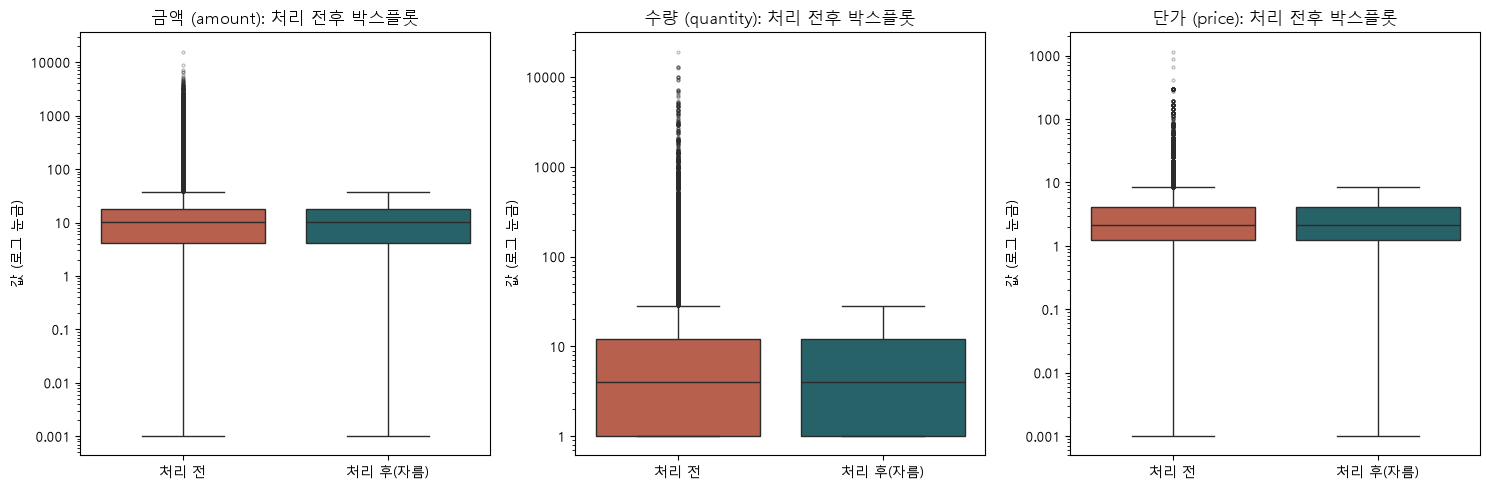

In [38]:
# 박스플롯: 상자 = 가운데 50%(Q1~Q3), 위쪽 점 = IQR 기준 이상치
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (col, title) in zip(axes, targets):
    data = pd.DataFrame({"처리 전": df[col], "처리 후(자름)": df[f"{col}_clipped"]})
    sns.boxplot(data=data, ax=ax, palette=["#C8553D", "#1D6B74"], flierprops={"markersize": 2, "alpha": 0.3})
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(plain)
    ax.set_title(f"{title}: 처리 전후 박스플롯")
    ax.set_ylabel("값 (로그 눈금)")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "boxplot_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

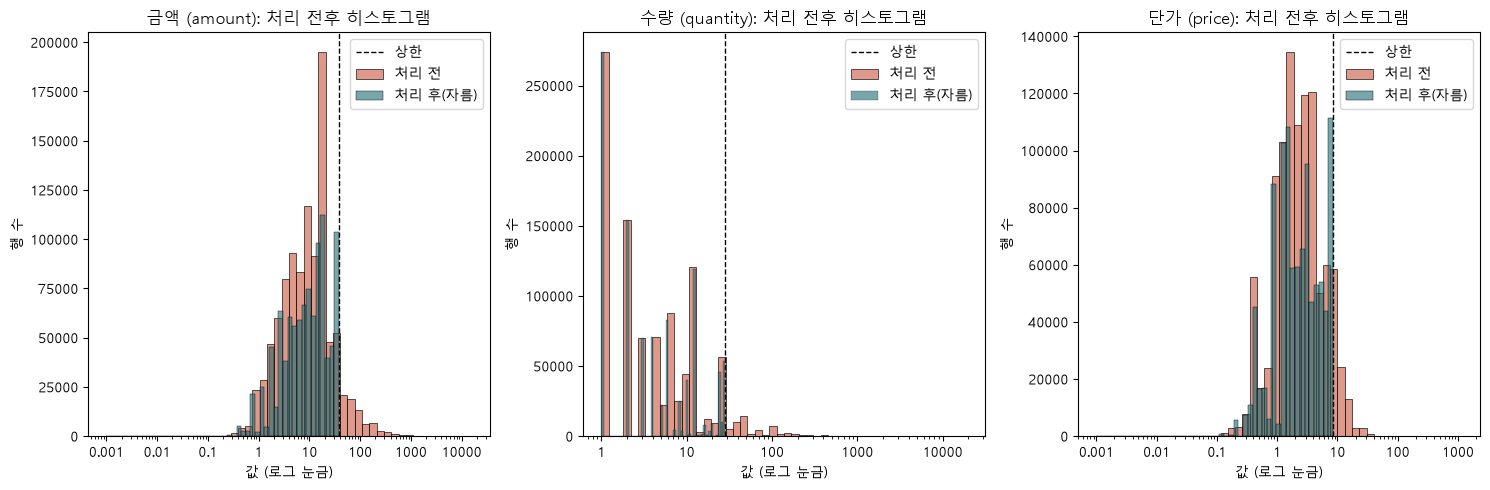

In [39]:
# 히스토그램: 값의 분포. 점선 = 정상 범위의 상한
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (col, title) in zip(axes, targets):
    sns.histplot(df[col], bins=50, log_scale=True, color="#C8553D", alpha=0.6, label="처리 전", ax=ax)
    sns.histplot(df[f"{col}_clipped"], bins=50, log_scale=True, color="#1D6B74", alpha=0.6, label="처리 후(자름)", ax=ax)
    ax.axvline(iqr_bounds(df[col])["upper"], color="black", linestyle="--", linewidth=1, label="상한")
    ax.xaxis.set_major_formatter(plain)
    ax.set_title(f"{title}: 처리 전후 히스토그램")
    ax.set_xlabel("값 (로그 눈금)")
    ax.set_ylabel("행 수")
    ax.legend()
fig.tight_layout()
fig.savefig(IMAGES_DIR / "histogram_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

> **해석**
>
> **수치 근거:** 박스플롯에서 처리 전(빨강)은 상자 위로 점(이상치)이 길게 이어져 `amount`는 최대 15,818까지 올라가지만, 처리 후(청록)에는 점이 사라지고 상한 38.06에서 끝납니다. 히스토그램에서 처리 전은 오른쪽으로 긴 꼬리가 이어지고, 처리 후에는 꼬리가 점선(상한) 위치에서 잘려 그 자리에 막대가 쌓입니다(잘린 행이 상한값으로 모이기 때문입니다). 수량은 정수라서 막대 사이가 비어 보입니다.
>
> **시사점:** 상자(가운데 50%)의 위치와 크기는 처리 전후에 같으므로, 자르기는 보통 주문의 분포는 건드리지 않고 극단값의 영향만 줄였다는 것을 확인할 수 있습니다.

## 3장-8. 이상치 처리 결론: 무엇을 왜 그렇게 했나

| 부류 | 처리 | 이유 |
|---|---|---|
| ① 비판매 코드(배송비·수기 입력·수수료·조정·테스트) | **제거** | 고객이 상품을 산 매출이 아닙니다. 지우지 않으면 매출과 이상치 분석이 오염됩니다. |
| ② 취소로 사라진 원 주문 | **규칙으로 제거** (같은 고객·상품·수량, 24시간 이내) | 이미 취소된 주문이 "판매"로 남으면 고객의 구매 금액(M)이 부풀려집니다. |
| ③ 진짜 대량 구매 | **지우지 않고 자른 새 컬럼**(`*_clipped`) | 진짜 고객 행동이고 금액의 절반 가까이를 차지해 지우면 안 됩니다. 평균·그래프에서만 영향을 줄입니다. |

- **RFM은 원본 `amount`로 계산합니다.** 자른 값(`amount_clipped`)은 통계·그래프용입니다. 큰 구매를 한 단골의 금액을 잘라 버리면 단골을 못 찾기 때문입니다.
- **IQR 기준**(`threshold=1.5`)은 관례값이며, 극단값에 흔들리지 않도록 평균·표준편차 대신 사분위수를 썼습니다.
- **한계:** 취소 짝 맞추기는 추정이라 부분 취소·24시간 이후 취소·고객 번호가 없는 행은 남아 있습니다. 어떤 코드가 비판매인지는 상품 설명을 보고 사람이 정한 목록입니다.

---

# 4장. 텍스트·이미지 피처

컴퓨터 모델은 숫자만 계산할 수 있습니다. 그래서 글자와 사진도 **숫자로 바꿔서 표의 컬럼으로 붙입니다.** 숫자·글자·사진이 섞인 데이터를 한 표에 모으는 작업입니다. 이 장은 상품 데이터(`fashion_analyzer`)에 아래 컬럼 4개를 추가합니다.

| 종류 | 새 컬럼 | 뜻 |
|---|---|---|
| 텍스트 | `name_word_count` | 상품명의 단어 수 |
| 텍스트 | `name_char_count` | 상품명의 글자 수 |
| 이미지 | `image_mean` | 사진 전체의 밝기 (0 = 검정 ~ 255 = 흰색) |
| 이미지 | `image_std` | 사진에서 밝은 부분과 어두운 부분이 얼마나 차이 나는가 (대비) |

## 4장-1. 텍스트 피처: 상품명의 단어 수와 글자 수

`add_text_features()`는 글자 컬럼에서 두 가지를 셉니다.
- **단어 수:** 공백으로 나눈 조각의 개수 (`str.split().str.len()`). 공백이 연달아 있어도 한 번의 구분으로 칩니다.
- **글자 수:** 앞뒤 공백을 뺀 길이 (`str.strip().str.len()`). 가운데 공백은 글자에 포함합니다.

상품명이 비어 있는 7행(2장-3에서 채우지 않기로 한 행)은 새 컬럼도 빈칸으로 둡니다.

In [40]:
import numpy as np
import matplotlib.pyplot as plt

fashion_analyzer.add_text_features("productDisplayName", prefix="name")
fashion_analyzer.df[["id", "productDisplayName", "name_word_count", "name_char_count"]].head()

,id,productDisplayName,name_word_count,name_char_count
0,15970,Turtle Check Men Navy Blue Shirt,6.0,32.0
1,39386,Peter England Men Party Blue Jeans,6.0,34.0
2,59263,Titan Women Silver Watch,4.0,24.0
3,21379,Manchester United Men Solid Black Track Pants,7.0,45.0
4,53759,Puma Men Grey T-shirt,4.0,21.0


In [41]:
text_cols = fashion_analyzer.df[["name_word_count", "name_char_count"]]
print(text_cols.describe().round(2).to_string())
print(f"\n상품명이 비어 있어 새 컬럼도 빈칸인 행: {text_cols['name_word_count'].isna().sum()}개")

names = fashion_analyzer.df["productDisplayName"]
one_word = fashion_analyzer.df.loc[fashion_analyzer.df["name_word_count"] == 1, "productDisplayName"]
print(f"\n▶ 단어 수가 1개뿐인 이름: {len(one_word)}개 (예: {one_word.head(3).tolist()})")
print(f"▶ 단어 수가 가장 많은 이름 ({int(text_cols['name_word_count'].max())}단어): {names[text_cols['name_word_count'].idxmax()]}")

       name_word_count  name_char_count
count         44417.00         44417.00
mean              5.79            34.67
std               1.40             8.52
min               1.00             7.00
25%               5.00            29.00
50%               6.00            34.00
75%               7.00            40.00
max              14.00            88.00

상품명이 비어 있어 새 컬럼도 빈칸인 행: 7개

▶ 단어 수가 1개뿐인 이름: 5개 (예: ['Ayaanay_Women_New_2013_Tunics_Size_Chart.jpg', 'RTV_LoadTest', 'Ayaanay_Women_New_2013_Tunics_Size_Chart.jpg'])
▶ 단어 수가 가장 많은 이름 (14단어): U.S. Polo Assn. Men Lavender & White Striped Linen Tailored Fit Smart Casual Shirt


> **해석**
>
> **수치 근거:** 상품명 44,417개의 단어 수는 평균 5.79개, 중앙값 6개이고 1~14개 범위입니다. 글자 수는 평균 34.67자, 중앙값 34자입니다. 평균과 중앙값이 거의 같아 한쪽으로 크게 치우치지 않은 분포입니다.
>
> **시사점:** 상품명은 대부분 "브랜드 + 성별 + 색 + 종류"를 6단어 안팎으로 적은 형태입니다. 단어 수가 1개뿐인 이름은 `RTV_LoadTest`처럼 상품명이 아니라 파일명·시험 데이터처럼 보이는 입력이라 이상한 값이므로, 분석에서 단어 수를 해석할 때 주의해야 합니다.

## 4장-2. 이미지는 숫자 상자: 손계산 예제

컴퓨터에서 사진은 **숫자 상자**입니다. 컬러 사진 한 장은 `세로 × 가로 × 3(빨강·초록·파랑)`개의 숫자이고, 각 숫자는 0(어두움)~255(밝음)입니다. 사진 여러 장을 같은 크기로 맞춰 쌓으면 **맨 앞에 "사진 번호" 축이 하나 더 생깁니다.**

```
사진 1장    →  shape (80, 60, 3)         세로 80, 가로 60, 색 3
사진 N장    →  shape (N, 80, 60, 3)      0번 축 = 사진 번호
```

원리를 손으로 따라갈 수 있게 **2×2 크기의 흑백 사진 3장**으로 연습합니다(색 축은 없습니다).

In [42]:
toy_images = np.array([
    [[  0,   0], [  0,   0]],        # 사진 1: 전부 검정
    [[100, 100], [200, 200]],        # 사진 2: 위쪽은 어둡고 아래쪽은 밝음
    [[255, 255], [255, 255]],        # 사진 3: 전부 흰색
])
print("shape:", toy_images.shape, "  → (사진 3장, 세로 2, 가로 2)")
print()
print("축 지정 없이 평균:", toy_images.mean(), "   ← 숫자 하나. 사진 구분 없이 12개를 전부 섞어 버림")
print("axis=0 평균:\n", toy_images.mean(axis=0), "   ← 사진 번호 축을 따라 평균: '평균 사진' 한 장")
print("axis=(1, 2) 평균:", toy_images.mean(axis=(1, 2)), "   ← 사진 번호는 남기고 세로·가로를 평균: 사진별 밝기")
print("axis=(1, 2) 표준편차:", toy_images.std(axis=(1, 2)))

shape: (3, 2, 2)   → (사진 3장, 세로 2, 가로 2)

축 지정 없이 평균: 135.0    ← 숫자 하나. 사진 구분 없이 12개를 전부 섞어 버림
axis=0 평균:
 [[118.33333333 118.33333333]
 [151.66666667 151.66666667]]    ← 사진 번호 축을 따라 평균: '평균 사진' 한 장
axis=(1, 2) 평균: [  0. 150. 255.]    ← 사진 번호는 남기고 세로·가로를 평균: 사진별 밝기
axis=(1, 2) 표준편차: [ 0. 50.  0.]


> **손으로 확인해 보세요**
>
> - **사진 1** (전부 0): 평균 0, 표준편차 0 → 검정, 대비 없음
> - **사진 2** (100, 100, 200, 200): 평균 = (100+100+200+200) ÷ 4 = **150**. 각 값과 평균의 차이는 −50, −50, +50, +50이고, 제곱의 평균이 2500이라 표준편차는 √2500 = **50**
> - **사진 3** (전부 255): 평균 255, 표준편차 0 → 흰색, 대비 없음
>
> `axis=(1, 2)`는 **"0번 축(사진 번호)은 남기고, 1번 축(세로)과 2번 축(가로)을 따라 계산하라"** 는 뜻입니다. 그래서 결과가 사진 수(3개)만큼 나옵니다. 컬러 사진이면 색 축(3번)이 하나 더 있으니 `axis=(1, 2, 3)`이 됩니다. 사진 3장의 평균이 반복문 없이 한 줄에 나오는 것이 **벡터 연산**입니다.
>
> (`np.std`의 기본값은 전체를 나누는 모집단 표준편차이고, pandas의 `.std()`는 하나 뺀 값으로 나누는 표본 표준편차라서 같은 데이터라도 값이 조금 다릅니다.)

같은 계산을 `extract_image_features()`로 하면 이렇게 나옵니다.

In [43]:
DataAnalyzer("예제").extract_image_features(toy_images)       # 예제는 CSV가 없으니 표 없이 계산만

,image_mean,image_std
0,0.0,0.0
1,150.0,50.0
2,255.0,0.0


## 4장-3. 상품 사진 읽어서 하나의 배열로 쌓기: `load_images()`

상품 사진은 `images/{id}.jpg` 파일입니다. 4만여 장을 전부 읽으면 오래 걸리므로 **무작위로 2,000장**을 뽑습니다(`random_state=42`로 고정해서 매번 같은 2,000장). `load_images()`가 하는 일은 다음과 같습니다.

1. 파일을 `matplotlib`의 `imread()`로 읽어 숫자 배열로 바꿉니다.
2. 크기가 `(80, 60, 3)`인 사진만 남깁니다. 크기나 색 개수가 다른 사진(흑백 등)은 **같은 크기가 아니면 하나의 상자로 쌓을 수 없어서** 건너뜁니다.
3. `np.stack`으로 `(N, 80, 60, 3)` 모양의 큰 상자 하나로 쌓습니다.

> 파일을 한 장씩 읽는 것은 파일 입출력이라 반복이 필요합니다. **평균·표준편차 계산에는 반복문을 쓰지 않습니다**(4장-4).

In [44]:
sample_ids = fashion_analyzer.df["id"].sample(n=2000, random_state=42).tolist()      # 무작위 2,000개 상품 번호
images, used_ids = fashion_analyzer.load_images(sample_ids, DATA_DIR / "fashion_small" / "images")

print(f"배열 모양: {images.shape}    자료형: {images.dtype}    값의 범위: {images.min()} ~ {images.max()}")
print(f"메모리: {images.nbytes / 1e6:.1f}MB")
print("\n첫 번째 사진의 왼쪽 위 2×2 픽셀 (각 픽셀은 빨강·초록·파랑 순서의 숫자 3개):")
print(images[0, :2, :2])
print()
print("▶ 사진 읽기 기록")
for key, value in fashion_analyzer.image_log.items():
    print(f"  {key}: {value}")

배열 모양: (1980, 80, 60, 3)    자료형: uint8    값의 범위: 0 ~ 255
메모리: 28.5MB

첫 번째 사진의 왼쪽 위 2×2 픽셀 (각 픽셀은 빨강·초록·파랑 순서의 숫자 3개):
[[[255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]]]

▶ 사진 읽기 기록
  요청한 id: 2000
  파일을 찾음: 2000
  쌓은 사진: 1980
  크기가 달라 건너뜀: 20
  건너뛴 사진의 크기: {'(80, 60)': 20}


> **해석**
>
> **수치 근거:** 2,000장의 파일을 모두 찾았고, 그중 1,980장이 `80×60` 컬러 사진이라 `(1980, 80, 60, 3)` 모양의 배열 하나(약 28.5MB)로 쌓았습니다. 나머지 20장은 색 축이 없는 흑백 사진(`80×60`)이라 건너뛰었습니다. 값은 0~255 정수(`uint8`)입니다.
>
> **시사점:** 이 배열의 `shape`이 곧 "사진 1,980장 × 세로 80 × 가로 60 × 색 3"이라는 뜻입니다. 사진 1장은 14,400개의 숫자로, 1,980장은 약 2,851만 개의 숫자로 바뀌었습니다. 이제 NumPy로 한꺼번에 계산할 수 있습니다.

## 4장-4. 사진별 평균·표준편차: 벡터 연산

`extract_image_features()` 안에서 핵심은 두 줄입니다.

```python
axes = tuple(range(1, pixels.ndim))        # 0번 축(사진 번호)만 남기고 나머지 축 전부 → (1, 2, 3)
pixels.mean(axis=axes)                      # 사진 1,980장의 평균이 한 번에 → 길이 1,980
pixels.std(axis=axes)                       # 사진 1,980장의 표준편차가 한 번에 → 길이 1,980
```

- `image_mean` = 사진의 모든 숫자(14,400개)의 평균 → **전체적으로 얼마나 밝은가**
- `image_std` = 그 숫자들의 표준편차 → **밝은 부분과 어두운 부분이 얼마나 차이 나는가(대비)**

In [45]:
features = fashion_analyzer.extract_image_features(images, ids=used_ids)       # ids를 주면 표(df)의 image_mean, image_std 컬럼에도 들어감
print(f"사진 {images.shape[0]:,}장 → 결과 {len(features):,}행   (같아야 함)")

one = images[0]                                                               # 사진 한 장만 따로 계산해서 비교
print(f"\n첫 번째 사진을 따로 계산:   평균 {one.mean():.4f}, 표준편차 {one.std():.4f}")
print(f"표에 들어간 첫 번째 값:      평균 {features.loc[0, 'image_mean']:.4f}, 표준편차 {features.loc[0, 'image_std']:.4f}")

approx = fashion_analyzer.extract_image_features(images, step=2)              # step=2: 가로·세로를 한 칸씩 건너뛰어 4분의 1만 사용 (ids 없이 → 표는 안 바뀜)
diff = (approx["image_mean"] - features["image_mean"]).abs()
print(f"\nstep=2(다운샘플)와 전부 쓴 평균의 차이: 평균 {diff.mean():.3f}, 최대 {diff.max():.3f}  (0~255 범위에서)")

df = fashion_analyzer.df
print(f"\n상품 표 {len(df):,}행 중 image_mean이 채워진 행: {df['image_mean'].notna().sum():,}개 (사진이 없는 행은 빈칸)")
features[["image_mean", "image_std"]].describe().round(2)

사진 1,980장 → 결과 1,980행   (같아야 함)

첫 번째 사진을 따로 계산:   평균 179.5915, 표준편차 91.8407
표에 들어간 첫 번째 값:      평균 179.5915, 표준편차 91.8407



step=2(다운샘플)와 전부 쓴 평균의 차이: 평균 0.294, 최대 4.324  (0~255 범위에서)

상품 표 44,424행 중 image_mean이 채워진 행: 1,980개 (사진이 없는 행은 빈칸)


,image_mean,image_std
count,1980.00,1980.00
mean,214.70,63.63
std,22.55,21.41
min,95.45,5.52
25%,200.18,49.74
50%,217.01,65.74
75%,231.73,79.97
max,254.30,113.03


> **해석**
>
> **수치 근거:** 사진 1,980장에서 결과도 1,980개입니다. 사진 한 장만 따로 계산한 값과 표에 들어간 값이 일치합니다. 평균 밝기는 평균 214.7이고(범위 95.4 ~ 254.3), 표준편차는 평균 63.6입니다(범위 5.5 ~ 113.0). `step=2`로 4분의 1만 써도 평균 밝기 차이는 평균 0.29로 거의 같습니다.
>
> **시사점:** 밝기 평균이 214.7로 높은 것은 상품 사진 대부분이 **흰 배경**이기 때문입니다. 따라서 `image_mean`은 상품 색이 아니라 "배경과 상품을 합친 전체 밝기"입니다. 사진 1,980장 모두를 반복문 없이 한 번에 계산했고, 결과가 2,000장 중 사진이 있는 행의 컬럼으로 붙었습니다.

## 4장-5. 눈으로 확인: 숫자가 사진과 맞는가

가장 어두운/밝은 사진과 대비가 가장 작은/큰 사진을 5장씩 직접 띄워서, 계산한 숫자가 눈으로 본 느낌과 맞는지 확인합니다.

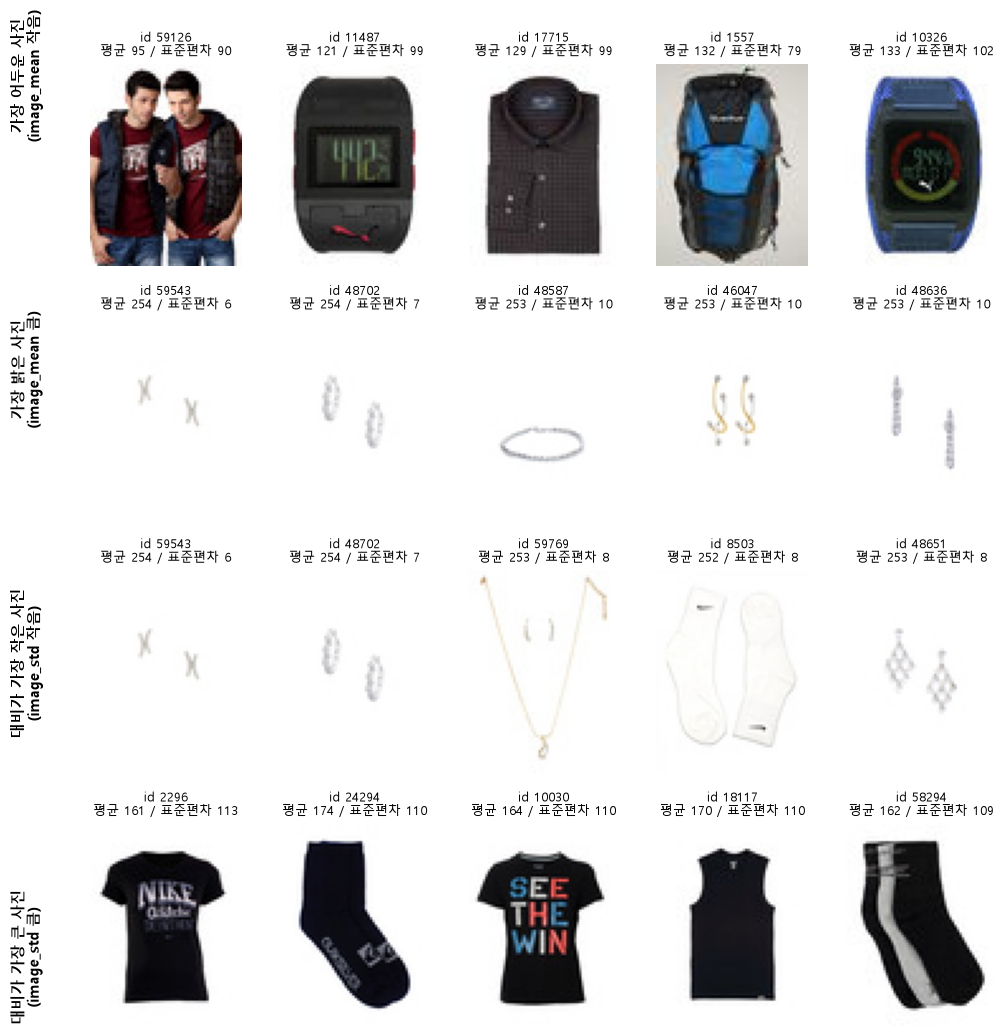

In [46]:
means = features["image_mean"].to_numpy()
stds = features["image_std"].to_numpy()
order_mean = np.argsort(means)            # 평균이 작은 사진부터 순서대로 사진 번호를 나열
order_std = np.argsort(stds)

groups = [
    ("가장 어두운 사진\n(image_mean 작음)", order_mean[:5]),
    ("가장 밝은 사진\n(image_mean 큼)", order_mean[-5:][::-1]),
    ("대비가 가장 작은 사진\n(image_std 작음)", order_std[:5]),
    ("대비가 가장 큰 사진\n(image_std 큼)", order_std[-5:][::-1]),
]
fig, axes = plt.subplots(4, 5, figsize=(11, 12.5))
for row, (title, picks) in enumerate(groups):
    for col, k in enumerate(picks):
        ax = axes[row, col]
        ax.imshow(images[k])
        ax.set_title(f"id {used_ids[k]}\n평균 {means[k]:.0f} / 표준편차 {stds[k]:.0f}", fontsize=9)
        ax.axis("off")
    fig.text(0.015, 0.87 - row * 0.235, title, rotation=90, va="center", ha="center", fontsize=11, fontweight="bold")
fig.subplots_adjust(left=0.07, hspace=0.25)
fig.savefig(IMAGES_DIR / "image_samples.png", dpi=150, bbox_inches="tight")
plt.show()

> **해석**
>
> **수치 근거:** 평균이 가장 낮은 사진들(평균 95~133)은 검정 시계, 진한 셔츠, 가방처럼 어두운 상품이 화면을 꽉 채우거나 흰색이 아닌 배경의 사진입니다. 평균이 가장 높은 사진들(평균 253~254)은 흰 배경 위에 작은 귀걸이·팔찌만 있는 사진입니다. 대비(표준편차)가 가장 작은 사진들(6~8)은 흰 배경 위의 가는 액세서리나 흰색 양말처럼 **배경과 비슷하게 밝은 상품**이고, 가장 큰 사진들(109~113)은 흰 배경 위의 검은 티셔츠·양말처럼 **배경과 상품이 강하게 대비되는** 사진입니다.
>
> **시사점:** 숫자가 눈으로 본 느낌과 맞습니다. **평균은 전체 밝기, 표준편차는 밝고 어두운 부분의 대비**라는 해석이 확인됩니다. 두 사진(id 59543, 48702)은 "가장 밝은" 줄과 "대비가 가장 작은" 줄에 모두 나옵니다. 흰 배경 위주의 사진은 밝기가 높고 대비는 낮게 함께 움직이는 경향이 있다는 뜻이며, 이 관계는 5장(통계 분석)에서 상관계수로 확인합니다.

## 4장-6. 정리와 한계

- **추가한 컬럼 4개:** 텍스트 `name_word_count`, `name_char_count`, 이미지 `image_mean`, `image_std`. 숫자·범주·날짜에 더해 글자와 사진까지 숫자로 바꿔 한 표에 모았습니다.
- **읽기와 계산을 분리:** 사진 파일을 한 장씩 읽는 부분(`load_images`)만 반복이 필요하고, 평균·표준편차 계산(`extract_image_features`)은 `axis=(1, 2, 3)` 배열 연산 한 번입니다.
- **표본:** 2,000장을 무작위로 뽑아 1,980장을 썼습니다(흑백 20장 제외). 상품 표 44,424행 중 사진 피처는 1,980행에만 있고 나머지는 빈칸입니다.
- **한계:** 이 데이터는 의류 중심이고 흰 배경 사진이 많아 `image_mean`이 높게 치우쳐 있습니다. 이 값은 "상품의 색"이 아니라 "사진 전체의 밝기"이며, 상품 이미지 데이터는 거래 데이터와 연결되지 않아 구매 행동과의 관계는 분석하지 않습니다.